# 08 -- Model Explainability

## Objective

Investigate the factors contributing to predictions from the sigmoid-calibrated HistGradientBoosting model. Permutation importance will be used to assess the contribution of individual input features to predictive performance. The analysis will support model interpretation and inform subsequent fairness evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)

df = pd.read_csv(
    "../data/processed/loan_data_feature_engineered.csv"
)

model = joblib.load(
    "../models/hist_gradient_boosting_calibrated.joblib"
)

print("Dataset shape:", df.shape)
print("Calibrated model loaded successfully.")

Dataset shape: (44988, 14)
Calibrated model loaded successfully.


# Recreating the test set

In [2]:
target = "Loan Status"

numeric_features = [
    "Age",
    "Employee Experience",
    "Log_Person_Income",
    "Loan Amount",
    "Credit History",
    "Credit Score",
    "Loan_to_Income"
]

categorical_features = [
    "Gender",
    "Education",
    "Home Ownership",
    "Loan Intent",
    "Previous Loan"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Test observations:", len(X_test))

Test observations: 8998


# Calculating permutation importance


In [3]:
importance_result = permutation_importance(
    estimator=model,
    X=X_test,
    y=y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance Mean": importance_result.importances_mean,
    "Importance Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(5))

,Feature,Importance Mean,Importance Std
0,Previous Loan,0.27884,0.00702
1,Log_Person_Income,0.04006,0.00142
2,Loan_to_Income,0.03811,0.00125
3,Home Ownership,0.02926,0.00125
4,Loan Intent,0.01396,0.00072
5,Credit Score,0.00738,0.00074
6,Loan Amount,0.00314,0.00044
7,Age,0.00225,0.00044
8,Credit History,0.00043,0.00027
9,Employee Experience,0.00024,0.00023


# Plot the top 10 features

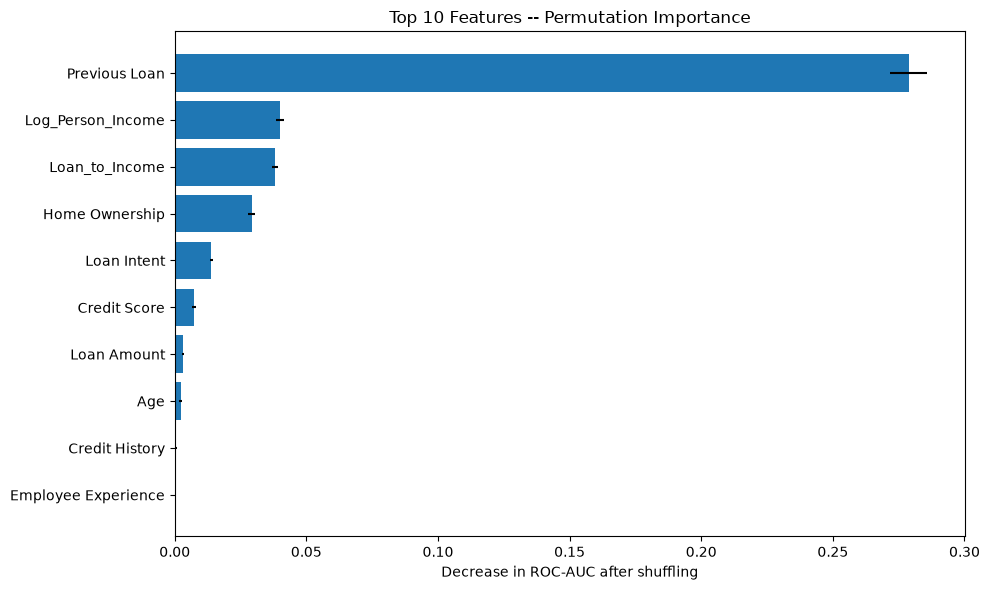

In [5]:
top_features = importance_df.head(10).sort_values(
    "Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.title("Top 10 Features -- Permutation Importance")
plt.grid(False)
plt.tight_layout()
plt.show()

# Saving the results

In [6]:
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(
    reports_dir / "permutation_feature_importance.csv",
    index=False
)

print("Feature importance saved.")

Feature importance saved.


Compare target rates

In [7]:
previous_loan_summary = (
    df.groupby("Previous Loan")["Loan Status"]
    .agg(["count", "mean"])
    .reset_index()
)

previous_loan_summary["Target Rate (%)"] = (
    previous_loan_summary["mean"] * 100
)

display(
    previous_loan_summary[
        ["Previous Loan", "count", "Target Rate (%)"]
    ].round(2)
)

,Previous Loan,count,Target Rate (%)
0,No,22133,45.18
1,Yes,22855,0.00


Visualise the relationship

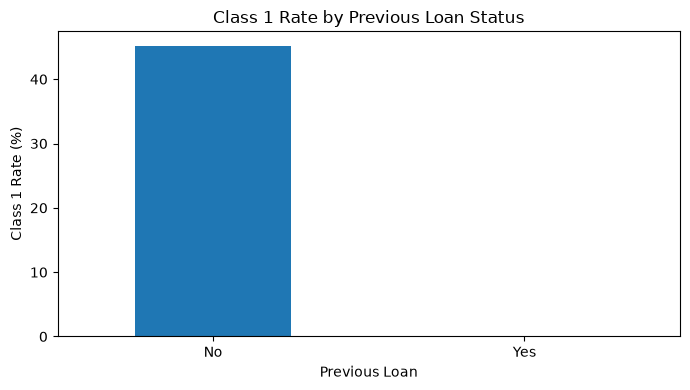

In [8]:
target_rates = (
    df.groupby("Previous Loan")["Loan Status"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(7, 4))
target_rates.plot(kind="bar")
plt.xlabel("Previous Loan")
plt.ylabel("Class 1 Rate (%)")
plt.title("Class 1 Rate by Previous Loan Status")
plt.xticks(rotation=0)
plt.grid(False)
plt.tight_layout()
plt.show()

### Interpretation of Permutation Feature Importance

Permutation importance identified `Previous Loan` as the dominant predictor of the calibrated HistGradientBoosting model, with a mean ROC-AUC decrease of 0.27884. `Log_Person_Income`, `Loan_to_Income`, and `Home Ownership` were the next most influential features. In contrast, Gender, Education, and Employee Experience showed very small decreases in ROC-AUC when shuffled.

These findings describe the model's reliance on the available predictors rather than causal relationships. The unusually high importance of `Previous Loan` warrants further investigation to establish its relationship with the target and confirm that it is available at the time of a new loan decision. The low measured importance of demographic features does not, by itself, establish that the model is fair; fairness must be evaluated separately.

Verify the target distribution within each category

In [9]:
pd.crosstab(
    df["Previous Loan"],
    df["Loan Status"],
    margins=True
)

Loan Status,0,1,All
Previous Loan,,,
No,12133,10000,22133
Yes,22855,0,22855
All,34988,10000,44988


Check the relationship on the training and test sets

In [10]:
print("TRAINING SET")
display(pd.crosstab(
    X_train["Previous Loan"],
    y_train,
    normalize="index"
).round(4))

print("TEST SET")
display(pd.crosstab(
    X_test["Previous Loan"],
    y_test,
    normalize="index"
).round(4))

TRAINING SET


Loan Status,0,1
Previous Loan,,
No,0.548,0.452
Yes,1.000,0.000


TEST SET


Loan Status,0,1
Previous Loan,,
No,0.5487,0.4513
Yes,1.0000,0.0000


# Training a model without Previous Loan

In [11]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# Remove Previous Loan from the feature lists
numeric_features_no_previous = numeric_features.copy()

categorical_features_no_previous = [
    col for col in categorical_features
    if col != "Previous Loan"
]

features_no_previous = (
    numeric_features_no_previous
    + categorical_features_no_previous
)

X_no_previous = df[features_no_previous].copy()
y = df[target].copy()

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X_no_previous,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor_np = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features_no_previous
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features_no_previous
        )
    ]
)

tuned_hgb = HistGradientBoostingClassifier(
    min_samples_leaf=30,
    max_leaf_nodes=15,
    max_iter=300,
    learning_rate=0.15,
    l2_regularization=0.1,
    random_state=42
)

pipeline_np = Pipeline([
    ("preprocessor", preprocessor_np),
    ("classifier", tuned_hgb)
])

model_no_previous = CalibratedClassifierCV(
    estimator=pipeline_np,
    method="sigmoid",
    cv=5,
    n_jobs=-1
)

model_no_previous.fit(X_train_np, y_train_np)

prob_np = model_no_previous.predict_proba(X_test_np)[:, 1]
pred_np = (prob_np >= 0.5).astype(int)

print("Model without Previous Loan")
print("-" * 35)
print(f"Accuracy:          {accuracy_score(y_test_np, pred_np):.4f}")
print(f"Precision:         {precision_score(y_test_np, pred_np, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_test_np, pred_np, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_test_np, pred_np, zero_division=0):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test_np, prob_np):.4f}")
print(f"Average Precision: {average_precision_score(y_test_np, prob_np):.4f}")
print(f"Brier Score:       {brier_score_loss(y_test_np, prob_np):.4f}")
print(f"Log Loss:          {log_loss(y_test_np, prob_np):.4f}")

Model without Previous Loan
-----------------------------------
Accuracy:          0.8834
Precision:         0.9342
Recall:            0.5115
F1-score:          0.6611
ROC-AUC:           0.8823
Average Precision: 0.7917
Brier Score:       0.0897
Log Loss:          0.2992


# do comparison and save results

In [12]:
comparison = pd.DataFrame([
    {
        "Model": "Calibrated HGB with Previous Loan",
        "ROC-AUC": 0.9626,
        "Average Precision": 0.8975,
        "Brier Score": 0.0627,
        "Log Loss": 0.1916
    },
    {
        "Model": "Calibrated HGB without Previous Loan",
        "ROC-AUC": roc_auc_score(y_test_np, prob_np),
        "Average Precision": average_precision_score(y_test_np, prob_np),
        "Brier Score": brier_score_loss(y_test_np, prob_np),
        "Log Loss": log_loss(y_test_np, prob_np)
    }
])

display(comparison.round(4))

comparison.to_csv(
    "../reports/previous_loan_sensitivity_comparison.csv",
    index=False
)

,Model,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Calibrated HGB with Previous Loan,0.9626,0.8975,0.0627,0.1916
1,Calibrated HGB without Previous Loan,0.8823,0.7917,0.0897,0.2992


In [14]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion matrix -- model without Previous Loan")
print(confusion_matrix(y_test_np, pred_np))

print("\nClassification report")
print(classification_report(y_test_np, pred_np, digits=4))

Confusion matrix -- model without Previous Loan
[[6926   72]
 [ 977 1023]]

Classification report
              precision    recall  f1-score   support

           0     0.8764    0.9897    0.9296      6998
           1     0.9342    0.5115    0.6611      2000

    accuracy                         0.8834      8998
   macro avg     0.9053    0.7506    0.7953      8998
weighted avg     0.8892    0.8834    0.8699      8998



In [15]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = (prob_np >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test_np, predictions),
        "Precision": precision_score(
            y_test_np, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_np, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_np, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.8665,0.7177,0.6585,0.6868
1,0.4,0.8810,0.8413,0.5725,0.6813
2,0.5,0.8834,0.9342,0.5115,0.6611
3,0.6,0.8808,0.9715,0.4775,0.6403
4,0.7,0.8791,0.9893,0.4610,0.6289


### Classification Threshold Analysis

Threshold analysis was conducted on the calibrated HistGradientBoosting model excluding `Previous Loan`. The results demonstrate a trade-off between precision and recall. At a threshold of 0.30, recall increased to 0.6585 and the F1-score reached 0.6868, compared with recall of 0.5115 and an F1-score of 0.6611 at the default threshold of 0.50. However, precision decreased from 0.9342 to 0.7177.

The threshold of 0.50 achieved the highest accuracy among the five evaluated thresholds, at 0.8834. Nevertheless, accuracy alone is insufficient for selecting an operational threshold. The final threshold should be determined using validation data and the relative costs of classification errors, with final performance evaluated on an untouched test set.

In [16]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

threshold_path = reports_dir / "threshold_analysis_without_previous_loan.csv"

threshold_df.to_csv(threshold_path, index=False)

print(f"Threshold analysis saved to: {threshold_path}")
display(threshold_df.round(4))

Threshold analysis saved to: ../reports/threshold_analysis_without_previous_loan.csv


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.8665,0.7177,0.6585,0.6868
1,0.4,0.8810,0.8413,0.5725,0.6813
2,0.5,0.8834,0.9342,0.5115,0.6611
3,0.6,0.8808,0.9715,0.4775,0.6403
4,0.7,0.8791,0.9893,0.4610,0.6289


Plot the precision–recall trade-off

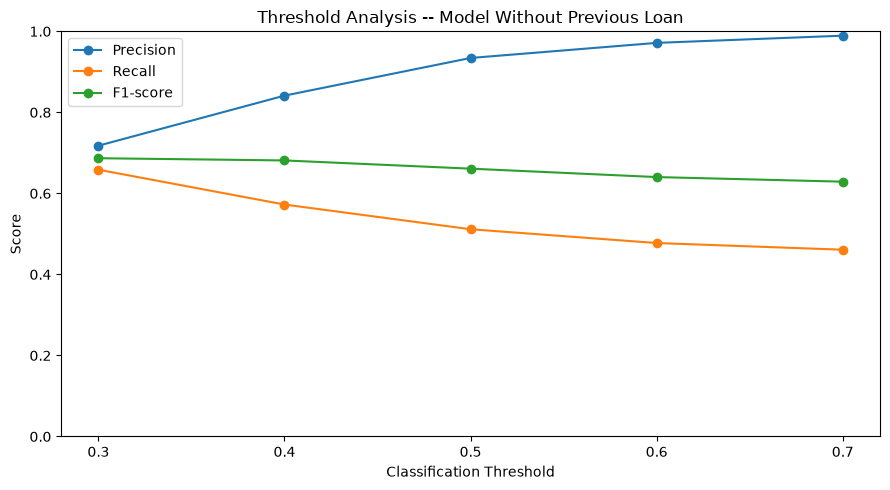

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Analysis -- Model Without Previous Loan")
plt.xticks(threshold_df["Threshold"])
plt.ylim(0, 1)
plt.grid(False)
plt.legend()
plt.tight_layout()
plt.show()

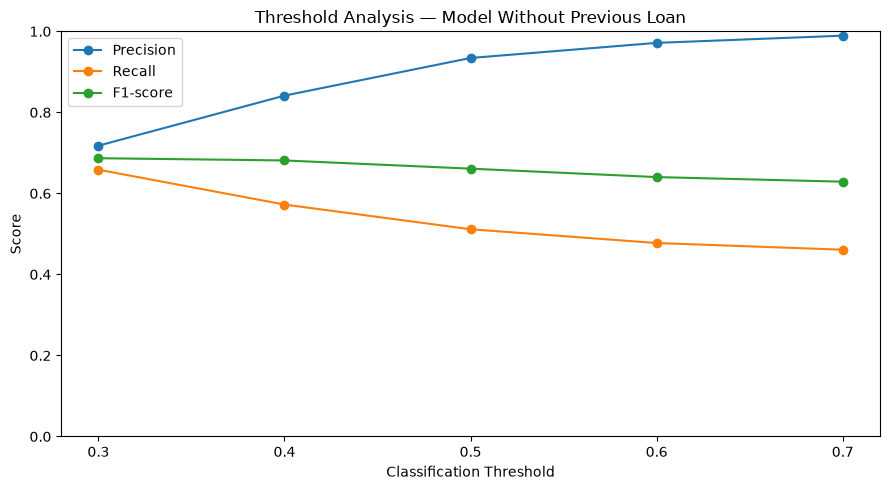

Threshold plot saved.


In [20]:
figure_path = Path("../reports/figures")
figure_path.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Analysis — Model Without Previous Loan")
plt.xticks(threshold_df["Threshold"])
plt.ylim(0, 1)
plt.grid(False)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_path / "threshold_analysis_without_previous_loan.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Threshold plot saved.")

In [21]:
# Predicted probabilities from the calibrated model
individual_results = X_test_np.copy()

individual_results["Actual Class"] = y_test_np
individual_results["Predicted Probability Class 1"] = prob_np
individual_results["Prediction at 0.50"] = pred_np

# High probability
high_idx = individual_results[
    "Predicted Probability Class 1"
].idxmax()

# Probability closest to 0.50
middle_idx = (
    individual_results["Predicted Probability Class 1"]
    .sub(0.50)
    .abs()
    .idxmin()
)

# Low probability
low_idx = individual_results[
    "Predicted Probability Class 1"
].idxmin()

selected_indices = [high_idx, middle_idx, low_idx]

individual_examples = individual_results.loc[
    selected_indices
].copy()

individual_examples.insert(
    0,
    "Example",
    ["High probability", "Near threshold", "Low probability"]
)

display(individual_examples.round(4))

,Example,Age,Employee Experience,Log_Person_Income,Loan Amount,Credit History,Credit Score,Loan_to_Income,Gender,Education,Home Ownership,Loan Intent,Actual Class,Predicted Probability Class 1,Prediction at 0.50
43487,High probability,22,0,9.5372,3803,4,666,0.2743,male,High School,RENT,HOMEIMPROVEMENT,1,1.0000,1
8641,Near threshold,21,2,10.4785,8000,2,512,0.2251,female,Associate,RENT,MEDICAL,0,0.4999,0
6635,Low probability,22,1,11.0218,6400,4,652,0.1046,female,Associate,OWN,VENTURE,0,0.0005,0


In [22]:
for example_name, row_idx in zip(
    ["High probability", "Near threshold", "Low probability"],
    selected_indices
):
    print(f"\n{'=' * 55}")
    print(example_name)
    print(f"{'=' * 55}")

    print(
        "Actual class:",
        individual_results.loc[row_idx, "Actual Class"]
    )

    print(
        "Predicted probability of class 1:",
        round(
            individual_results.loc[
                row_idx, "Predicted Probability Class 1"
            ],
            4
        )
    )

    print("\nInput features:")
    display(X_test_np.loc[[row_idx]].T.rename(
        columns={row_idx: "Feature value"}
    ))


High probability
Actual class: 1
Predicted probability of class 1: 1.0

Input features:


,Feature value
Age,22
Employee Experience,0
Log_Person_Income,9.537195
Loan Amount,3803
Credit History,4
Credit Score,666
Loan_to_Income,0.274288
Gender,male
Education,High School
Home Ownership,RENT



Near threshold
Actual class: 0
Predicted probability of class 1: 0.4999

Input features:


,Feature value
Age,21
Employee Experience,2
Log_Person_Income,10.47847
Loan Amount,8000
Credit History,2
Credit Score,512
Loan_to_Income,0.225092
Gender,female
Education,Associate
Home Ownership,RENT



Low probability
Actual class: 0
Predicted probability of class 1: 0.0005

Input features:


,Feature value
Age,22
Employee Experience,1
Log_Person_Income,11.021755
Loan Amount,6400
Credit History,4
Credit Score,652
Loan_to_Income,0.104592
Gender,female
Education,Associate
Home Ownership,OWN


# Calculate model-agnostic permutation effects for each example